# Diabetic Retinopathy using CNN 

## 1. Import Libraries

In [1]:
import tensorflow as tf 
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt 
from tensorflow.keras.optimizers import Adam
import numpy as np
import pickle
from sklearn.model_selection import train_test_split

I0000 00:00:1784478513.133070    4251 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784478515.290622    4251 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784478550.824114    4251 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load data

In [2]:
with open("../../../data/processed/aptos/sample_50/sample_dataset.pkl", "rb") as f: 
    data = pickle.load(f)

In [3]:
print(type(data))

<class 'dict'>


In [4]:
data.keys()

dict_keys(['data', 'labels', 'class_names'])

In [5]:
data['labels']

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4])

In [6]:
data['class_names']

['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']

In [7]:
data['data'].shape

(250, 300, 300, 3)

## 3. Data Preprocessing

In [8]:
# Unpack từ dict
X = data['data']           # numpy array ảnh
y = data['labels']         # numpy array nhãn  
class_names = data['class_names']

In [9]:
class_names

['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(x_train.shape)
print(x_test.shape)

(200, 300, 300, 3)
(50, 300, 300, 3)


In [11]:
y_train

array([1, 0, 2, 1, 1, 0, 4, 1, 1, 4, 1, 3, 4, 2, 2, 1, 1, 2, 3, 1, 4, 0,
       2, 2, 2, 3, 1, 2, 0, 0, 3, 3, 1, 1, 3, 0, 1, 1, 2, 1, 4, 1, 2, 2,
       3, 3, 2, 4, 1, 0, 3, 0, 4, 3, 0, 0, 0, 2, 3, 0, 0, 1, 0, 1, 4, 2,
       0, 2, 4, 1, 0, 4, 4, 3, 1, 4, 4, 3, 4, 4, 1, 0, 1, 2, 2, 2, 4, 1,
       3, 0, 0, 1, 4, 2, 0, 2, 1, 3, 4, 2, 2, 1, 4, 3, 0, 4, 2, 3, 0, 1,
       3, 4, 2, 1, 0, 1, 3, 0, 0, 0, 3, 1, 1, 3, 1, 2, 0, 2, 0, 3, 3, 0,
       0, 1, 2, 0, 0, 2, 2, 4, 4, 3, 3, 3, 4, 0, 3, 0, 1, 4, 4, 2, 4, 3,
       2, 3, 4, 4, 2, 4, 4, 1, 2, 4, 4, 2, 1, 3, 3, 3, 4, 3, 4, 0, 3, 0,
       3, 1, 4, 0, 2, 1, 2, 2, 3, 0, 2, 1, 3, 3, 4, 4, 0, 3, 2, 2, 0, 3,
       4, 4])

In [12]:
num_classes = 5
x_train, x_test = x_train / 255.0, x_test / 255.0
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test  = tf.keras.utils.to_categorical(y_test , num_classes)

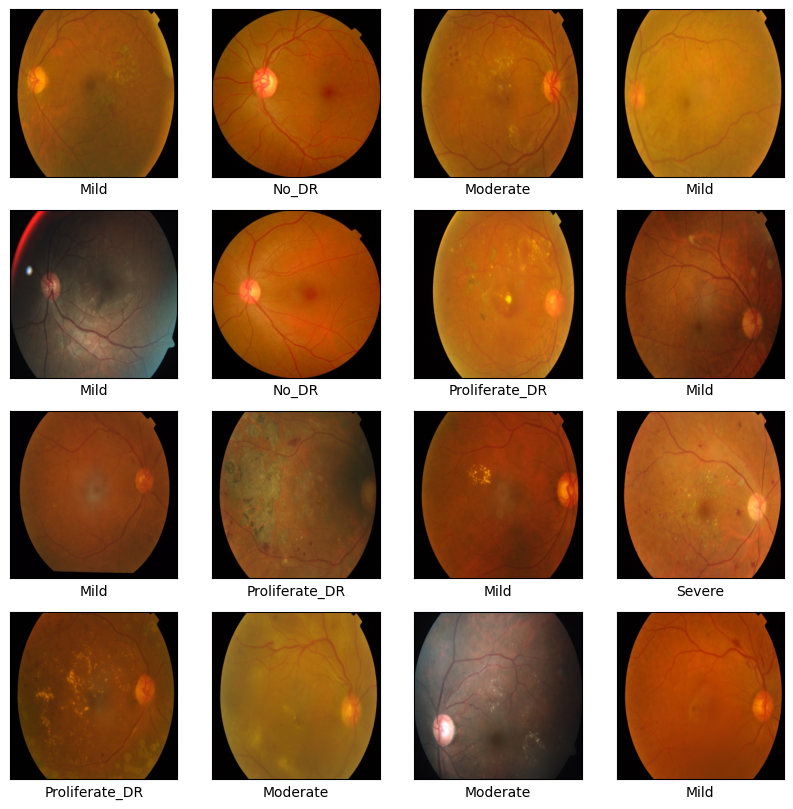

In [13]:
plt.figure(figsize=(10,10))
for i in range(16): 
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

## 3. Building the CNN Model

In [14]:
model = models.Sequential([
    
    # Block 1
    layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(300, 300, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 150x150

    # Block 2
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 75x75

    # Block 3
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 37x37

    # Block 4
    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 18x18

    # Block 5
    layers.Conv2D(256, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),  # → 9x9

    layers.Flatten(),
    layers.Dropout(0.5),

    layers.Dense(512, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.summary()

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1784478583.500249    4251 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 300, 300, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 300, 300, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 37, 37, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 18, 18, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    10,617,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,601,349 (44.26 MB)

 Trainable params: 11,599,877 (44.25 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [15]:
model.compile(optimizer=Adam(learning_rate=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/cnn_sample_50_aptos.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(x_train, y_train,
                    epochs=20,
                    batch_size=8,
                    validation_split=0.2,
                    callbacks=callbacks,
                    verbose=2)

Epoch 1/20


I0000 00:00:1784478591.091647    4618 service.cc:153] XLA service 0x73c82403cef0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784478591.091694    4618 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784478591.280610    4618 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784478591.952449    4618 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784478592.103943    4618 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4889__.83
I0000 00:00:1784478607.696195    4618 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1784478619.761471    4620 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.06GiB (r


Epoch 1: val_accuracy improved from None to 0.17500, saving model to ../../../data/models/cnn_sample_50_aptos.keras

Epoch 1: finished saving model to ../../../data/models/cnn_sample_50_aptos.keras
20/20 - 58s - 3s/step - accuracy: 0.3187 - loss: 12.0822 - val_accuracy: 0.1750 - val_loss: 3.7832 - learning_rate: 0.0010
Epoch 2/20

Epoch 2: val_accuracy improved from 0.17500 to 0.27500, saving model to ../../../data/models/cnn_sample_50_aptos.keras

Epoch 2: finished saving model to ../../../data/models/cnn_sample_50_aptos.keras
20/20 - 3s - 135ms/step - accuracy: 0.3625 - loss: 8.7448 - val_accuracy: 0.2750 - val_loss: 6.4634 - learning_rate: 0.0010
Epoch 3/20

Epoch 3: val_accuracy improved from 0.27500 to 0.30000, saving model to ../../../data/models/cnn_sample_50_aptos.keras

Epoch 3: finished saving model to ../../../data/models/cnn_sample_50_aptos.keras
20/20 - 3s - 131ms/step - accuracy: 0.4125 - loss: 5.1523 - val_accuracy: 0.3000 - val_loss: 13.1685 - learning_rate: 0.0010
Epo

## 4. Visualiza Training

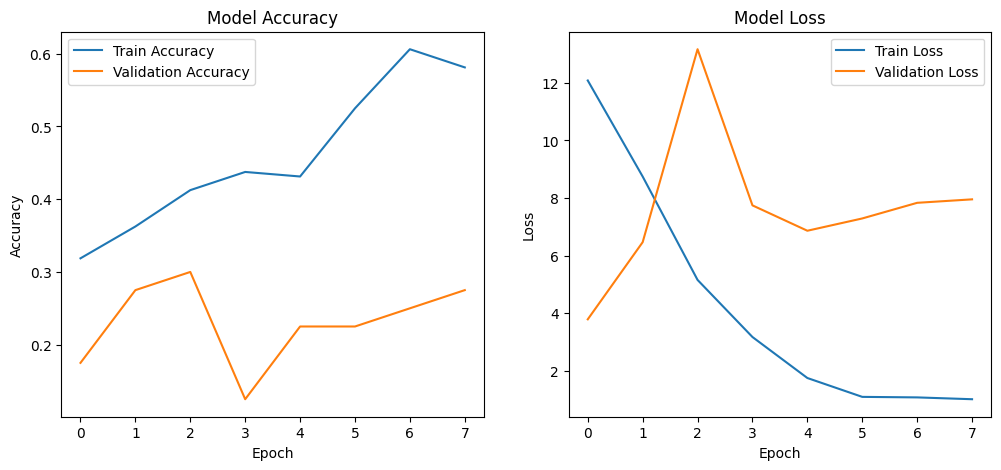

In [16]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

## 5. Evaluate on Test set

In [17]:
test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=8, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}') 

W0000 00:00:1784478671.752355    4621 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.04GiB (rounded to 1117127168)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1784478671.752499    4621 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1784478671.752503    4621 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 87, Chunks in use: 85. 21.8KiB allocated for chunks. 21.2KiB in use in bin. 4.5KiB client-requested in use in bin.
I0000 00:00:1784478671.752507    4621 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 12, Chunks in use: 11. 6.0KiB allocated for chunks. 5.5KiB in use in bin. 5.5KiB client-requested in use in bin.
I0000 00:00:1784478671.752509    4621 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 24, Chunks in use: 24. 24.2KiB allocated for

Test Loss: 3.8395
Test Accuracy: 0.1800
